In [92]:
print("Hi")

Hi


In [93]:
from typing import Annotated, TypedDict
import operator

from langgraph.graph import StateGraph, START, END
from langgraph.types import Send

In [94]:
def show_graph(compiled_graph, *, xray=False):
    """Print the generated graph as Mermaid text."""

    print(
        compiled_graph.get_graph(
            xray=xray
        ).draw_mermaid()
    )


In [95]:
class OrderState(TypedDict):
    product: str
    quantity: int
    inventory_status: str
    total_price: float
    final_response: str

In [96]:
PRODUCT_CATALOG = {
    "Keyboard": {"stock": 5, "unit_price": 500.0},
    "Mouse": {"stock": 10, "unit_price": 250.0},
}

In [97]:
def check_inventory(state: OrderState):
    print("Checking inventory...")

    product = PRODUCT_CATALOG[state["product"]]
    is_available = product["stock"] >= state["quantity"]

    return {
        "inventory_status": (
            "Available" if is_available else "Unavailable"
        )
    }

In [98]:
def calculate_price(state: OrderState):
    print("Calculating price...")

    if state["inventory_status"] != "Available":
        return {"total_price": 0.0}

    unit_price = PRODUCT_CATALOG[state["product"]]["unit_price"]

    return {
        "total_price": state["quantity"] * unit_price
    }


In [99]:
order_subgraph_builder = StateGraph(OrderState)

In [100]:
order_subgraph_builder.add_node(
    "check_inventory",
    check_inventory,
)

order_subgraph_builder.add_node(
    "calculate_price",
    calculate_price,
)

In [101]:
order_subgraph_builder.add_edge(
    START,
    "check_inventory",
)

order_subgraph_builder.add_edge(
    "check_inventory",
    "calculate_price",
)

order_subgraph_builder.add_edge(
    "calculate_price",
    END,
)

In [102]:
order_subgraph = order_subgraph_builder.compile()

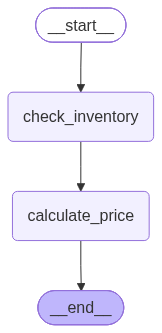

In [103]:
order_subgraph

### 1.3 Parent graph nodes

In [104]:
def validate_request(state: OrderState):
    print("Validating request...")

    if state["product"] not in PRODUCT_CATALOG:
        raise ValueError(f"Unknown product: {state['product']}")

    if state["quantity"] <= 0:
        raise ValueError("Quantity must be greater than zero.")

    return {}

In [105]:
def create_final_response(state: OrderState):
    if state["inventory_status"] == "Available":
        response = (
            f"{state['quantity']} {state['product']} ordered. "
            f"Total Price: ₹{state['total_price']:,.2f}"
        )
    else:
        response = (
            f"Order not placed. {state['quantity']} "
            f"{state['product']} are not available."
        )

    return {
        "final_response": response
    }


In [106]:
order_builder = StateGraph(OrderState)

In [107]:
order_builder.add_node(
    "validate_request",
    validate_request,
)

In [108]:
# The complete compiled subgraph becomes one parent node.
order_builder.add_node(
    "order_processing",
    order_subgraph,
)

In [109]:
order_builder.add_node(
    "final_response",
    create_final_response,
)

In [110]:
order_builder.add_edge(
    START,
    "validate_request",
)

order_builder.add_edge(
    "validate_request",
    "order_processing",
)

order_builder.add_edge(
    "order_processing",
    "final_response",
)

order_builder.add_edge(
    "final_response",
    END,
)

In [111]:
order_graph = order_builder.compile()

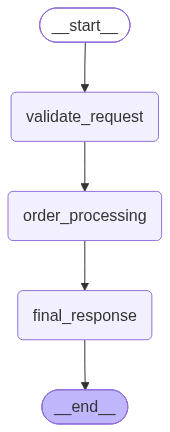

In [112]:
order_graph

In [113]:
show_graph(
    order_graph,
    xray=True,
)


---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	validate_request(validate_request)
	final_response(final_response)
	__end__([<p>__end__</p>]):::last
	__start__ --> validate_request;
	order_processing\3acalculate_price --> final_response;
	validate_request --> order_processing\3acheck_inventory;
	final_response --> __end__;
	subgraph order_processing
	order_processing\3acheck_inventory(check_inventory)
	order_processing\3acalculate_price(calculate_price)
	order_processing\3acheck_inventory --> order_processing\3acalculate_price;
	end
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



In [114]:
def run_order_workflow():
    result = order_graph.invoke(
        {
            "product": "Keyboard",
            "quantity": 2,
        }
    )

    print(result["final_response"])

    return result


In [116]:
order_result = run_order_workflow()

Validating request...
Checking inventory...
Calculating price...
2 Keyboard ordered. Total Price: ₹1,000.00


In [117]:
def run_order_workflow():
    result = order_graph.invoke(
        {
            "product": "Monitor",
            "quantity": 5,
        }
    )

    print(result["final_response"])

    return result

In [118]:
order_result = run_order_workflow()


Validating request...


ValueError: Unknown product: Monitor

In [119]:
def run_order_workflow():
    result = order_graph.invoke(
        {
            "product": "Keyboard",
            "quantity": 50,
        }
    )

    print(result["final_response"])

    return result

In [120]:
order_result = run_order_workflow()


Validating request...
Checking inventory...
Calculating price...
Order not placed. 50 Keyboard are not available.


In [121]:
order_result

{'product': 'Keyboard',
 'quantity': 50,
 'inventory_status': 'Unavailable',
 'total_price': 0.0,
 'final_response': 'Order not placed. 50 Keyboard are not available.'}

## 2. Parallel Research Subgraph with `Send`

In [123]:
from dotenv import load_dotenv
from langchain_groq import ChatGroq

load_dotenv()

model = ChatGroq(
    model="openai/gpt-oss-20b",
    temperature=0,
)

In [124]:
class ParentState(TypedDict):
    topics: list[str]
    research_results: Annotated[
        list[str],
        operator.add,
    ]
    final_answer: str